## 03 - Exploratory analysis

Looks at ratings, review volume and developer replies over time, and saves the charts.
Only counts and metadata are shown here, never review texts.

Input: `data/processed/trenord_reviews_clean.csv`

Output: six charts in `reports/figures/`

In [1]:
# --- IMPORTS ---
import pandas as pd
import matplotlib.pyplot as plt

# --- LOAD PROCESSED DATA ---
# We load the CSV saved by 02_cleaning.ipynb
df = pd.read_csv("../data/processed/trenord_reviews_clean.csv")

# Make sure date column is parsed as datetime
df["date"] = pd.to_datetime(df["date"])

print(f"Loaded {len(df)} reviews")
print(f"Columns: {df.columns.tolist()}")
print(f"Date range: {df['date'].min().date()} → {df['date'].max().date()}")

Loaded 7329 reviews
Columns: ['review_id', 'rating', 'text', 'thumbs_up', 'app_version', 'date', 'has_reply', 'reply_text', 'reply_date', 'year', 'month', 'day_of_week', 'year_month', 'language', 'text_clean', 'word_count', 'text_lemmatized']
Date range: 2015-05-05 → 2026-08-04


In [2]:
# --- QUICK OVERVIEW ---
# Before plotting anything, we get a quick summary of the data
# to understand what we are working with.

print("=== BASIC STATS ===")
print(f"Total reviews      : {len(df):,}")
print(f"Average rating     : {df['rating'].mean():.2f} / 5.0")
print(f"Median rating      : {df['rating'].median():.1f} / 5.0")
print(f"Reviews with reply : {df['has_reply'].sum():,} ({df['has_reply'].mean()*100:.1f}%)")
print(f"Avg word count     : {df['word_count'].mean():.0f} words per review")

print("\n=== RATING DISTRIBUTION ===")
print(df["rating"].value_counts().sort_index())

print("\n=== LANGUAGE DISTRIBUTION ===")
print(df["language"].value_counts())

print("\n=== REVIEWS PER YEAR ===")
print(df["year"].value_counts().sort_index())

=== BASIC STATS ===
Total reviews      : 7,329
Average rating     : 2.26 / 5.0
Median rating      : 1.0 / 5.0
Reviews with reply : 3,052 (41.6%)
Avg word count     : 20 words per review

=== RATING DISTRIBUTION ===
rating
1    4075
2     745
3     454
4     654
5    1401
Name: count, dtype: int64

=== LANGUAGE DISTRIBUTION ===
language
it         6951
unknown     363
en            5
la            5
fr            2
es            1
mi            1
pt            1
Name: count, dtype: int64

=== REVIEWS PER YEAR ===
year
2015     190
2016     160
2017     245
2018     460
2019    1086
2020     825
2021     708
2022     920
2023     955
2024     776
2025     678
2026     326
Name: count, dtype: int64


### Key findings from overview
- **The median rating is the lowest possible score**: more than half of all reviews give 1 star.
- **The developer reply rate is high overall**, but the over-time chart below shows it is concentrated in the early years.
- **2019 is the year with the most reviews**, worth investigating why.
- **Reviews are long enough for NLP**: see the average word count printed above.

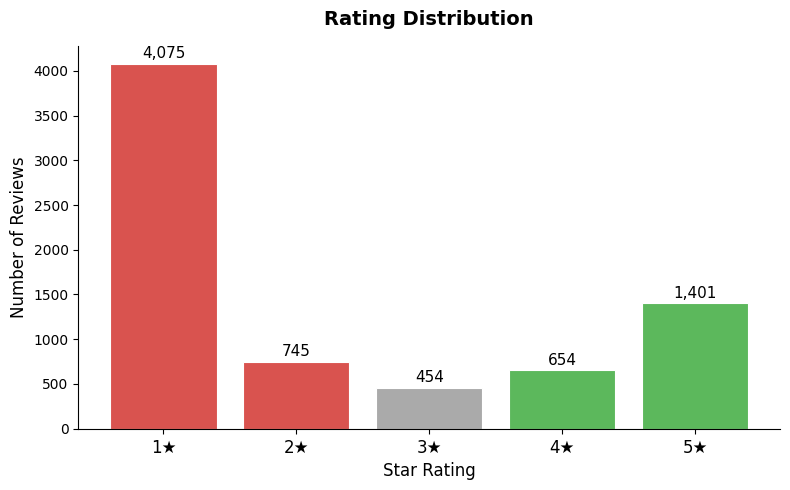

Average rating : 2.26 / 5.0
Total reviews  : 7,329


In [3]:
# --- CHART 1: RATING DISTRIBUTION ---
fig, ax = plt.subplots(figsize=(8, 5))

# Count reviews per star rating, sorted from 1 to 5
rating_counts = df["rating"].value_counts().sort_index()

# Red for negative (1-2 stars), grey for neutral (3), green for positive (4-5)
colors = ["#d9534f", "#d9534f", "#aaaaaa", "#5cb85c", "#5cb85c"]

bars = ax.bar(rating_counts.index, rating_counts.values, color=colors, edgecolor="white", linewidth=0.8)

# Show the exact count on top of each bar
for bar, count in zip(bars, rating_counts.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,  # horizontal center of the bar
        bar.get_height() + 30,               # slightly above the bar
        f"{count:,}",                        # formatted number e.g. "3,994"
        ha="center", va="bottom", fontsize=11
    )

ax.set_title("Rating Distribution", fontsize=14, fontweight="bold", pad=15)
ax.set_xlabel("Star Rating", fontsize=12)
ax.set_ylabel("Number of Reviews", fontsize=12)
ax.set_xticks([1, 2, 3, 4, 5])
ax.set_xticklabels(["1★", "2★", "3★", "4★", "5★"], fontsize=12)

# Remove top and right borders for a cleaner look
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig("../reports/figures/chart_rating_distribution.png", dpi=150)
plt.show()

print(f"Average rating : {df['rating'].mean():.2f} / 5.0")
print(f"Total reviews  : {len(df):,}")

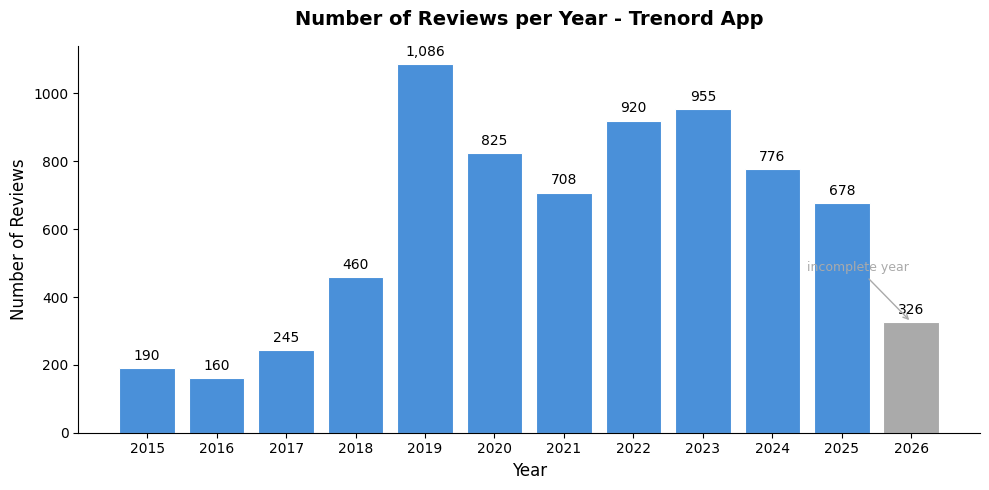

In [4]:
# --- CHART 2: NUMBER OF REVIEWS PER YEAR ---
# We count how many reviews were posted each year.
# Spikes can indicate major events: bad app updates, service disruptions, etc.
# 2026 is shown in a different color because the year is not complete yet.

reviews_per_year = df.groupby("year").size()

# Assign a color to each bar: grey for 2026 (incomplete), blue for all other years
colors = ["#4a90d9" if year < 2026 else "#aaaaaa" for year in reviews_per_year.index]

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(reviews_per_year.index, reviews_per_year.values, color=colors, edgecolor="white", linewidth=0.8)

# Show the exact count on top of each bar
for year, count in reviews_per_year.items():
    ax.text(year, count + 15, f"{count:,}", ha="center", va="bottom", fontsize=10)

# Add a text annotation on the 2026 bar to explain the grey color
ax.annotate(
    "incomplete year",
    xy=(2026, reviews_per_year[2026]),        # point to the 2026 bar
    xytext=(2024.5, reviews_per_year[2026] + 150),  # position of the label
    fontsize=9,
    color="#aaaaaa",
    arrowprops=dict(arrowstyle="->", color="#aaaaaa")
)

ax.set_title("Number of Reviews per Year - Trenord App", fontsize=14, fontweight="bold", pad=15)
ax.set_xlabel("Year", fontsize=12)
ax.set_ylabel("Number of Reviews", fontsize=12)
ax.set_xticks(reviews_per_year.index)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig("../reports/figures/chart_reviews_per_year.png", dpi=150)
plt.show()

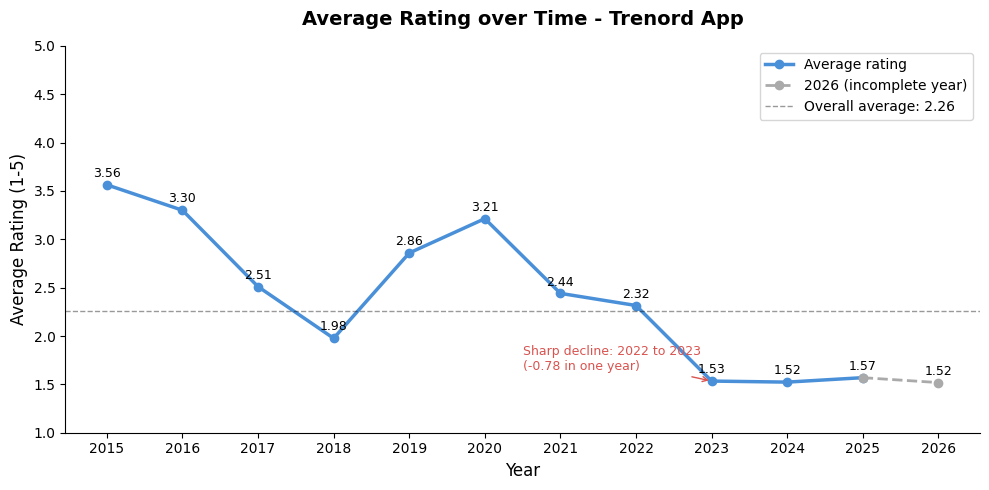

In [5]:
# --- CHART 3: AVERAGE RATING OVER TIME ---
# We use a line chart instead of bars because:
# - bars imply the value starts from zero, which is misleading for averages
# - a line is the correct choice when showing a trend over time
# 2026 is shown as a dashed line because the year is not complete.

yearly_stats = df.groupby("year").agg(
    avg_rating=("rating", "mean"),
    review_count=("rating", "count")
).reset_index()

# Split complete years from incomplete 2026
complete = yearly_stats[yearly_stats["year"] < 2026]
incomplete = yearly_stats[yearly_stats["year"] >= 2025]  # 2025-2026 for the dashed segment

fig, ax = plt.subplots(figsize=(10, 5))

# Solid line for complete years
ax.plot(
    complete["year"], complete["avg_rating"],
    color="#4a90d9", linewidth=2.5, marker="o", markersize=6,
    label="Average rating"
)

# Dashed line for 2026 (incomplete year)
ax.plot(
    incomplete["year"], incomplete["avg_rating"],
    color="#aaaaaa", linewidth=2, marker="o", markersize=6,
    linestyle="--", label="2026 (incomplete year)"
)

# Add the exact value next to each data point
for _, row in yearly_stats.iterrows():
    ax.text(
        row["year"], row["avg_rating"] + 0.05,  # slightly above the point
        f"{row['avg_rating']:.2f}",
        ha="center", va="bottom", fontsize=9
    )

# Add a horizontal reference line at the overall average
overall_avg = df["rating"].mean()
ax.axhline(
    y=overall_avg,
    color="black", linestyle="--", linewidth=1, alpha=0.4,
    label=f"Overall average: {overall_avg:.2f}"
)

ax.set_title("Average Rating over Time - Trenord App", fontsize=14, fontweight="bold", pad=15)
ax.set_xlabel("Year", fontsize=12)
ax.set_ylabel("Average Rating (1-5)", fontsize=12)
ax.set_xticks(yearly_stats["year"])
ax.set_ylim(1, 5)  # honest scale - shows the full rating range
ax.legend(fontsize=10)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Highlight the most recent sharp decline (at least 0.5 stars in one year) among complete years.
# Year and size are computed from the data, not hardcoded.
SHARP_DECLINE = -0.5
complete_by_year = complete.set_index("year")["avg_rating"]
yearly_change = complete_by_year.diff()
drop_year = int(yearly_change[yearly_change <= SHARP_DECLINE].index.max())
drop_rating = complete_by_year[drop_year]
ax.annotate(
    f"Sharp decline: {drop_year - 1} to {drop_year}\n({yearly_change[drop_year]:+.2f} in one year)",
    xy=(drop_year, drop_rating),
    xytext=(drop_year - 2.5, drop_rating + 0.11),
    fontsize=9,
    color="#d9534f",
    arrowprops=dict(arrowstyle="->", color="#d9534f")
)

plt.tight_layout()
plt.savefig("../reports/figures/chart_avg_rating_over_time.png", dpi=150)
plt.show()

### 4. Developer Reply Rate
We analyze how often Trenord responds to reviews.
We look at three dimensions:
1. Overall reply rate
2. Reply rate by star rating - does Trenord prioritize negative or positive reviews?
3. Reply rate over time - has Trenord become more or less responsive?

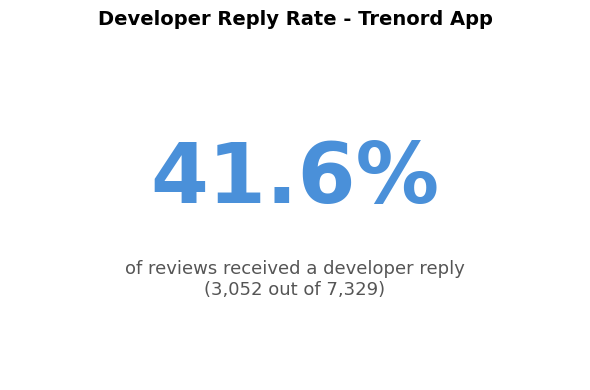

In [6]:
# --- CHART 4a: DEVELOPER REPLY RATE - OVERALL ---
# For a single percentage, a clean text summary is more immediate
# than a chart - the reader does not need to interpret anything.

total_reviews      = len(df)
reviews_with_reply = df["has_reply"].sum()
reply_rate         = reviews_with_reply / total_reviews * 100

fig, ax = plt.subplots(figsize=(6, 4))

# Show the big number in the center
ax.text(0.5, 0.6, f"{reply_rate:.1f}%",
        ha="center", va="center",
        fontsize=60, fontweight="bold", color="#4a90d9",
        transform=ax.transAxes)

ax.text(0.5, 0.3, f"of reviews received a developer reply\n({reviews_with_reply:,} out of {total_reviews:,})",
        ha="center", va="center",
        fontsize=13, color="#555555",
        transform=ax.transAxes)

ax.set_title("Developer Reply Rate - Trenord App", fontsize=14, fontweight="bold", pad=15)

# Hide axes - we don't need them for a text-based chart
ax.axis("off")

plt.tight_layout()
plt.savefig("../reports/figures/chart_reply_rate_overall.png", dpi=150)
plt.show()

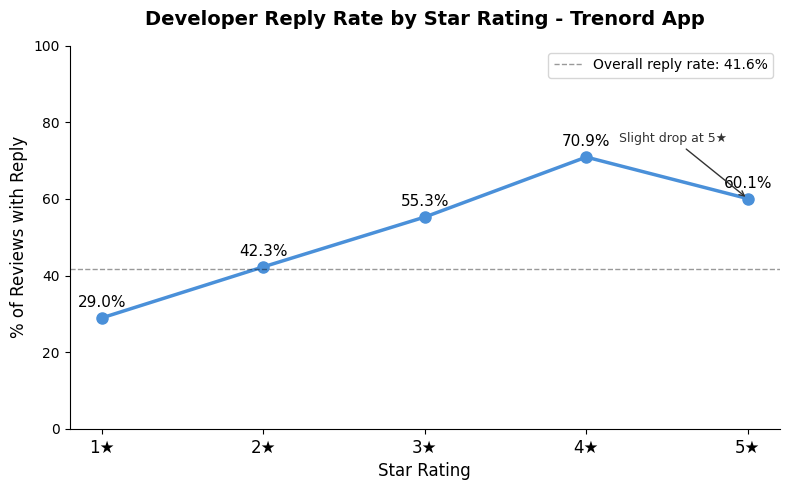

In [7]:
# --- CHART 4b: DEVELOPER REPLY RATE BY STAR RATING ---
# We use a line chart because we are showing a trend across an ordinal scale (1★ to 5★).
# The message is clear: the higher the rating, the more likely Trenord is to reply.

reply_by_rating = df.groupby("rating")["has_reply"].mean() * 100

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    reply_by_rating.index,
    reply_by_rating.values,
    color="#4a90d9", linewidth=2.5, marker="o", markersize=8
)

# Show the exact percentage next to each data point
for rating, pct in reply_by_rating.items():
    ax.text(
        rating, pct + 2,
        f"{pct:.1f}%",
        ha="center", va="bottom", fontsize=11
    )

# Add a reference line at the overall reply rate
overall_reply_rate = df["has_reply"].mean() * 100
ax.axhline(
    y=overall_reply_rate,
    color="black", linestyle="--", linewidth=1, alpha=0.4,
    label=f"Overall reply rate: {overall_reply_rate:.1f}%"
)

ax.set_title("Developer Reply Rate by Star Rating - Trenord App", fontsize=14, fontweight="bold", pad=15)
ax.set_xlabel("Star Rating", fontsize=12)
ax.set_ylabel("% of Reviews with Reply", fontsize=12)
ax.set_xticks([1, 2, 3, 4, 5])
ax.set_xticklabels(["1★", "2★", "3★", "4★", "5★"], fontsize=12)
ax.set_ylim(0, 100)  # percentage scale always 0 to 100
ax.legend(fontsize=10)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Annotate the interesting drop from 4★ to 5★
ax.annotate(
    "Slight drop at 5★",
    xy=(5, reply_by_rating[5]),
    xytext=(4.2, 75),
    fontsize=9,
    color="#333333",
    arrowprops=dict(arrowstyle="->", color="#333333")
)

plt.tight_layout()
plt.savefig("../reports/figures/chart_reply_rate_by_rating.png", dpi=150)
plt.show()

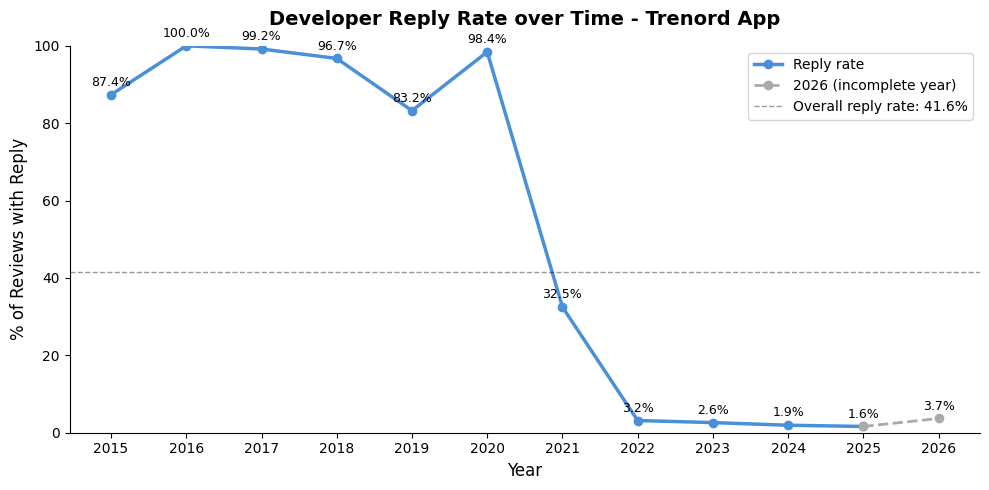

In [8]:
# --- CHART 5: DEVELOPER REPLY RATE OVER TIME ---
# We look at how Trenord's responsiveness has changed year by year.
# A drop in reply rate combined with a drop in average rating would indicate
# that Trenord became less engaged with users over time.

# Calculate reply rate per year
reply_by_year = df.groupby("year")["has_reply"].mean() * 100

# Split complete years from incomplete 2026
complete   = reply_by_year[reply_by_year.index < 2026]
incomplete = reply_by_year[reply_by_year.index >= 2025]  # overlap on 2025 connects the lines

fig, ax = plt.subplots(figsize=(10, 5))

# Solid line for complete years
ax.plot(
    complete.index, complete.values,
    color="#4a90d9", linewidth=2.5, marker="o", markersize=6,
    label="Reply rate"
)

# Dashed line for 2026 (incomplete year)
ax.plot(
    incomplete.index, incomplete.values,
    color="#aaaaaa", linewidth=2, marker="o", markersize=6,
    linestyle="--", label="2026 (incomplete year)"
)

# Show the exact percentage next to each data point
for year, pct in reply_by_year.items():
    ax.text(
        year, pct + 1.5,
        f"{pct:.1f}%",
        ha="center", va="bottom", fontsize=9
    )

# Add a reference line at the overall reply rate
overall_reply_rate = df["has_reply"].mean() * 100
ax.axhline(
    y=overall_reply_rate,
    color="black", linestyle="--", linewidth=1, alpha=0.4,
    label=f"Overall reply rate: {overall_reply_rate:.1f}%"
)

ax.set_title("Developer Reply Rate over Time - Trenord App", fontsize=14, fontweight="bold", pad=15)
ax.set_xlabel("Year", fontsize=12)
ax.set_ylabel("% of Reviews with Reply", fontsize=12)
ax.set_xticks(reply_by_year.index)
ax.set_ylim(0, 100)
ax.legend(fontsize=10)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig("../reports/figures/chart_reply_rate_over_time.png", dpi=150)
plt.show()

### Key finding - Reply Rate Collapse
Trenord replied to the large majority of reviews up to 2020 (values on the chart above).
The reply rate fell sharply in 2021 and has stayed close to zero since 2022.
The decline in average rating (chart 3) follows the end of this response strategy:
the two series move together, although this alone does not establish a causal link.

In [9]:
# --- MOST UPVOTED REVIEWS ---
# We show the top 10 reviews by thumbs up count.
# These are the reviews that other users found most representative.
# Review texts are not displayed in the notebook (privacy): we show upvotes,
# rating, date and length only. Full texts remain available in the CSV.

# Select and sort the top 10 most upvoted reviews
top_reviews = (
    df[["thumbs_up", "rating", "date", "word_count"]]
    .sort_values("thumbs_up", ascending=False)
    .head(10)
    .reset_index(drop=True)
)

# Format the date column for readability
top_reviews["date"] = top_reviews["date"].dt.strftime("%Y-%m-%d")

# Add star emoji to rating for immediate readability
top_reviews["rating"] = top_reviews["rating"].apply(lambda x: "★" * x)

# Rename columns for presentation
top_reviews.columns = ["Thumbs Up", "Rating", "Date", "Words"]

# Display with pandas styling:
# - highlight the thumbs up column for immediate visual hierarchy
(
    top_reviews.style
    .set_properties(subset=["Thumbs Up"], **{"font-weight": "bold", "text-align": "center"})
    .set_properties(subset=["Rating"], **{"text-align": "center"})
    .bar(subset=["Thumbs Up"], color="#4a90d9", vmin=0)
)

,Thumbs Up,Rating,Date,Words
0,87,★,2025-04-19,60
1,66,★,2024-06-05,67
2,66,★,2023-09-21,74
3,64,★,2023-07-02,70
4,64,★,2022-08-24,81
5,56,★,2024-09-18,63
6,54,★,2023-07-23,59
7,54,★,2023-08-06,57
8,53,★,2022-11-12,68
9,52,★,2022-02-17,77
